# Expressivity bottleneck on another dataset and model

`06_expressivity_bottleneck` tested the measure on the toy problem. Here it runs, unchanged, on a different dataset
and a different model, imported from `expressivity.py`:

* **data**: handwritten digits, 8×8 pixels, 10 classes (scikit-learn's `load_digits`, an offline, smaller cousin
  of MNIST). Each image is also shifted by one pixel in 4 directions, for 7,185 training images.
* **model**: an `nn.Sequential` MLP, 64 pixels → 4 hidden layers → 10 classes, in three versions that differ only in
  **`fc3`**, the third hidden layer: `pinch 1` (1 unit), `pinch 3` (3 units) and `uniform` (128 units everywhere).
  The measure is not told where the pinch is.

```python
from expressivity import linear_sites, measure, check, grow

sites = linear_sites(model)                 # [fc1→fc2, fc2→fc3, fc3→fc4, fc4→out]: every layer whose width can change
res   = measure(model, sites, fit_batches)  # one pass, 16 minibatches
res["fc3"].headroom                         # how fast the loss starts falling with one more fc3 unit
check(model, site, res["fc3"], fit_batches, check_batches)   # add it for real, measure the loss on other data
bigger = grow(model, site, res["fc3"], unit=i, scale=s)      # the grown model
```

Sections:

1. the data and the three models
2. which layer does the measure flag?
3. how early in training?
4. use it to grow: `pinch 1`, grown where the measure points, against growing somewhere else

In [1]:
import copy
import time
from collections import OrderedDict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.datasets import load_digits

from expressivity import check, grow, linear_sites, mean_loss, measure

try:
    from IPython.display import display
except ImportError:
    display = print

T_START = time.time()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)
INK, INK2, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e6e5e1"
MODEL_COLOR = {"pinch 1": "#6250d6", "pinch 3": "#a3a29b", "uniform": "#008300"}
SITE_COLOR = {"fc1": "#2a78d6", "fc2": "#1baf7a", "fc3": "#eb6834", "fc4": "#c4398f"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.labelsize": 9.5, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "axes.axisbelow": True, "lines.linewidth": 2, "figure.dpi": 110,
    "figure.constrained_layout.use": True,
})

## 1. The data and the three models

```python
images = load_digits().images / 16            # (1797, 8, 8), values 0..1
test   = 360 images;  train = the rest, each also shifted up / down / left / right by one pixel
x      = standardized pixels                  # (N, 64)

pinch 1 = MLP(64 → 128 → 128 → 1 → 128 → 10)  # fc3 has 1 unit
pinch 3 = MLP(64 → 128 → 128 → 3 → 128 → 10)  # fc3 has 3 units
uniform = MLP(64 → 128 → 128 → 128 → 128 → 10)
train each: Adam, lr 1e-3, batch 128, 40 epochs, a checkpoint every epoch
```

train (7185, 64)  test (360, 64)


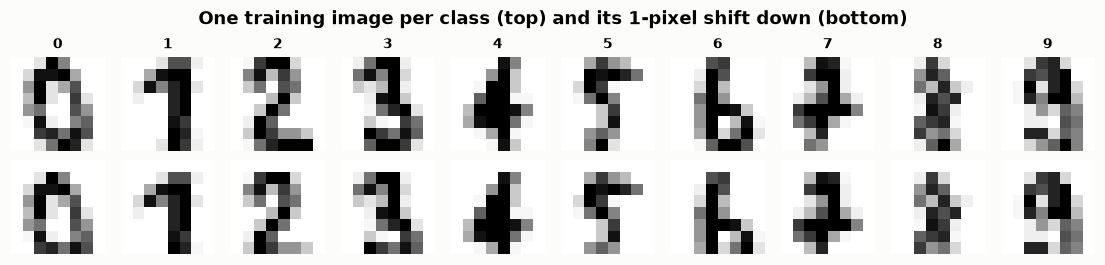

In [2]:
digits = load_digits()
images = torch.tensor(digits.images, dtype=torch.float32) / 16
labels = torch.tensor(digits.target)
order = torch.randperm(len(labels), generator=torch.Generator().manual_seed(0))
test_idx, train_idx = order[:360], order[360:]


def shifted(img):
    """The images plus their 1-pixel shifts in 4 directions (zero padding)."""
    out = [img]
    for dy, dx in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
        s = torch.roll(img, shifts=(dy, dx), dims=(1, 2))
        if dy == 1:
            s[:, 0, :] = 0
        if dy == -1:
            s[:, -1, :] = 0
        if dx == 1:
            s[:, :, 0] = 0
        if dx == -1:
            s[:, :, -1] = 0
        out.append(s)
    return torch.cat(out)


train_img = shifted(images[train_idx])
Y_TRAIN = labels[train_idx].repeat(5)
MEAN, STD = train_img.flatten(1).mean(0), train_img.flatten(1).std(0).clamp_min(0.05)
X_TRAIN = (train_img.flatten(1) - MEAN) / STD
X_TEST, Y_TEST = (images[test_idx].flatten(1) - MEAN) / STD, labels[test_idx]
print(f"train {tuple(X_TRAIN.shape)}  test {tuple(X_TEST.shape)}")

fig, axes = plt.subplots(2, 10, figsize=(10, 2.3))
for c in range(10):
    i = int((labels[train_idx] == c).nonzero()[0])
    for row, img in enumerate(shifted(images[train_idx][i:i + 1])[:2]):  # original, then shifted down
        axes[row, c].imshow(img, cmap="Greys", vmin=0, vmax=1)
        axes[row, c].axis("off")
    axes[0, c].set_title(str(c), fontsize=9)
fig.suptitle("One training image per class (top) and its 1-pixel shift down (bottom)", fontweight="bold")
plt.show()

trained all three in 3s


,train_loss,test_acc
pinch 1,0.8441,0.5306
pinch 3,0.0011,0.9611
uniform,0.0002,0.9861


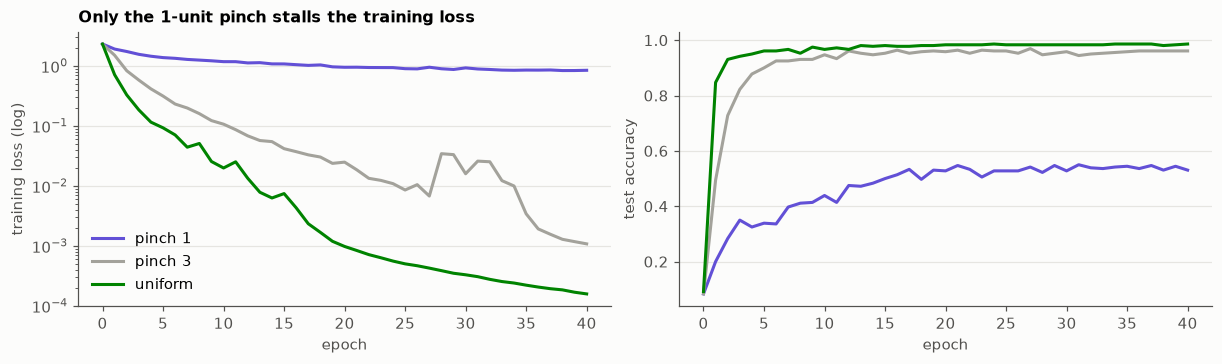

In [3]:
BATCH, EPOCHS = 128, 40
HIDDEN = {"pinch 1": [128, 128, 1, 128], "pinch 3": [128, 128, 3, 128], "uniform": [128, 128, 128, 128]}


def mlp(widths, seed=0):
    torch.manual_seed(seed)
    layers, d = OrderedDict(), 64
    for i, w in enumerate(widths, start=1):
        layers[f"fc{i}"], layers[f"relu{i}"], d = nn.Linear(d, w), nn.ReLU(), w
    layers["out"] = nn.Linear(d, 10)
    return nn.Sequential(layers)


def widths_of(model):
    return [m.out_features for name, m in model.named_children() if name.startswith("fc")]


@torch.no_grad()
def evaluate(model):
    model.eval()
    train_loss = F.cross_entropy(model(X_TRAIN), Y_TRAIN).item()
    test_acc = (model(X_TEST).argmax(-1) == Y_TEST).float().mean().item()
    return train_loss, test_acc


def train(model, epochs, seed=1, on_epoch=None):
    """Adam training. `on_epoch(model, epoch)` may return a new (grown) model; the optimizer is then rebuilt."""
    gen = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    rows, states = [dict(epoch=0, **dict(zip(["train_loss", "test_acc"], evaluate(model))))], {0: copy.deepcopy(model)}
    for epoch in range(1, epochs + 1):
        model.train()
        for idx in torch.randperm(len(Y_TRAIN), generator=gen).split(BATCH):
            loss = F.cross_entropy(model(X_TRAIN[idx]), Y_TRAIN[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
        if on_epoch is not None:
            grown = on_epoch(model, epoch)
            if grown is not model:
                model, opt = grown, torch.optim.Adam(grown.parameters(), lr=1e-3)
        rows.append(dict(epoch=epoch, **dict(zip(["train_loss", "test_acc"], evaluate(model))),
                         widths=widths_of(model)))
        states[epoch] = copy.deepcopy(model)
    return model, pd.DataFrame(rows), states


t0 = time.time()
RUNS = {name: train(mlp(w), EPOCHS) for name, w in HIDDEN.items()}
print(f"trained all three in {time.time() - t0:.0f}s")
display(pd.DataFrame({name: run[1].iloc[-1][["train_loss", "test_acc"]] for name, run in RUNS.items()}).T)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for name, (_, hist, _) in RUNS.items():
    axes[0].plot(hist.epoch, hist.train_loss, color=MODEL_COLOR[name], label=name)
    axes[1].plot(hist.epoch, hist.test_acc, color=MODEL_COLOR[name], label=name)
axes[0].set_yscale("log")
axes[0].set_ylabel("training loss (log)")
axes[1].set_ylabel("test accuracy")
for ax in axes:
    ax.set_xlabel("epoch")
axes[0].legend()
axes[0].set_title("Only the 1-unit pinch stalls the training loss", loc="left")
plt.show()

## 2. Which layer does the measure flag?

```python
fit   = 16 minibatches of 128 training images;  other = 16 more
for site in linear_sites(model):              # fc1→fc2, fc2→fc3, fc3→fc4, fc4→out
    res = measure(model, sites, fit)[site.layer]
    res.headroom                              # plot 1
    check(model, site, res, fit, other)       # plot 2: add the best unit (2 ReLU units), no training
```

measure + check in 0.2s


width  headroom  before        drop    scale   drop_%
model   layer                                                       
pinch 1 fc1      128    0.0020  0.8388  1.4000e-03    3.000   0.1675
        fc2      128    0.0060  0.8388  3.8000e-04    1.000   0.0459
        fc3        1    0.0244  0.8388  9.4600e-02   10.000  11.2773
        fc4      128    0.0000  0.8388  0.0000e+00    0.003   0.0000
pinch 3 fc1      128    0.0000  0.0009 -0.0000e+00   30.000  -0.4866
        fc2      128    0.0000  0.0009 -3.0000e-05   30.000  -3.8267
        fc3        3    0.0000  0.0009  4.0000e-05  100.000   3.8966
        fc4      128    0.0000  0.0009  0.0000e+00    0.003   0.0000
uniform fc1      128    0.0000  0.0001 -0.0000e+00  100.000  -0.8684
        fc2      128    0.0000  0.0001 -0.0000e+00  100.000  -0.0564
        fc3      128    0.0000  0.0001 -0.0000e+00  100.000  -0.0130
        fc4      128    0.0000  0.0001 -0.0000e+00  100.000  -0.0339

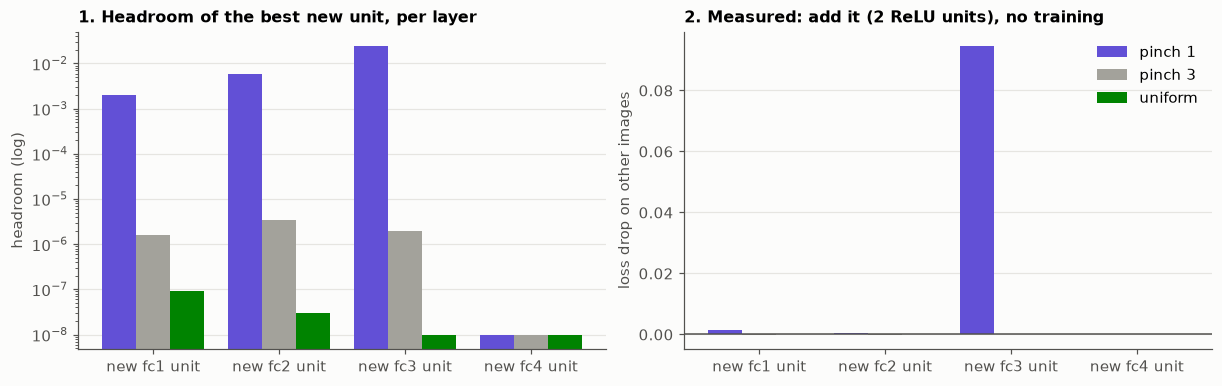

In [4]:
_order = torch.randperm(len(Y_TRAIN), generator=torch.Generator().manual_seed(4))
FIT = [(X_TRAIN[i], Y_TRAIN[i]) for i in _order[:2048].split(BATCH)]
OTHER = [(X_TRAIN[i], Y_TRAIN[i]) for i in _order[2048:4096].split(512)]
SITE_NAMES = [f"fc{i}" for i in range(1, 5)]

t0 = time.time()
rows = []
for name, (model, _, _) in RUNS.items():
    sites = linear_sites(model)
    res = measure(model, sites, FIT)
    for site in sites:
        rows.append(dict(model=name, layer=site.layer, width=model.get_submodule(site.layer).out_features,
                         headroom=res[site.layer].headroom, **check(model, site, res[site.layer], FIT, OTHER)))
table = pd.DataFrame(rows).set_index(["model", "layer"])
table["drop_%"] = 100 * table["drop"] / table["before"]
print(f"measure + check in {time.time() - t0:.1f}s")
display(table.drop(columns=["after"]).round(5))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
xs = np.arange(len(SITE_NAMES))
for ax, col, label in [(axes[0], "headroom", "headroom (log)"), (axes[1], "drop", "loss drop on other images")]:
    for k, name in enumerate(RUNS):
        vals = np.array([table.loc[(name, layer), col] for layer in SITE_NAMES])
        ax.bar(xs + (k - 1) * 0.27, np.maximum(vals, 1e-8) if col == "headroom" else vals, width=0.27,
               color=MODEL_COLOR[name], label=name)
    ax.set_xticks(xs, [f"new {layer} unit" for layer in SITE_NAMES])
    ax.grid(axis="x", visible=False)
    ax.set_ylabel(label)
axes[0].set_yscale("log")
axes[0].set_title("1. Headroom of the best new unit, per layer", loc="left")
axes[1].axhline(0, color=INK2, lw=1)
axes[1].set_title("2. Measured: add it (2 ReLU units), no training", loc="left")
axes[1].legend(loc="upper right")
plt.show()

## 3. How early in training?

```python
for epoch in [0, 1, 2, 3, 5, 10, 20, 30, 40]:
    measure(checkpoint[epoch], sites, fit)    # headroom per layer
```

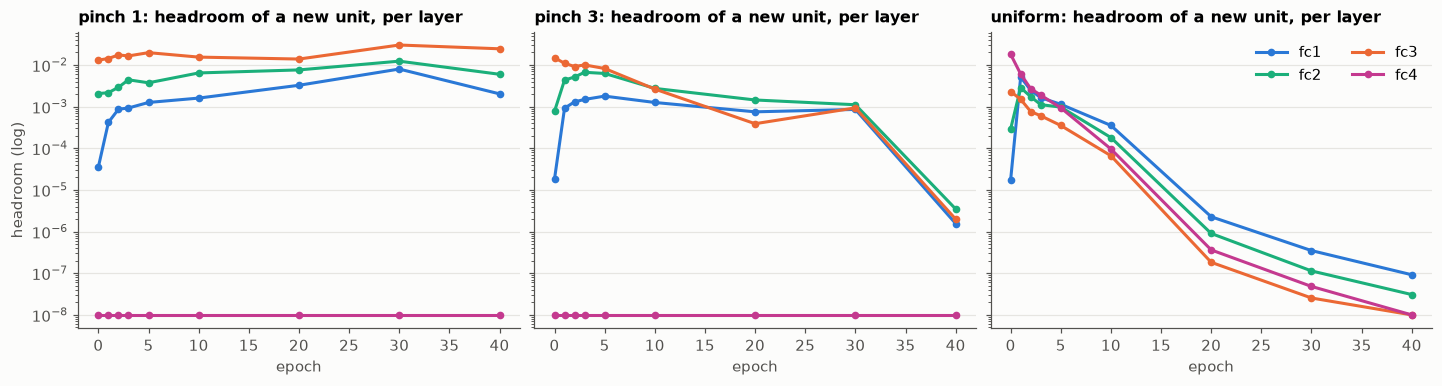

In [5]:
CHECK_EPOCHS = [0, 1, 2, 3, 5, 10, 20, 30, 40]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, (name, (_, _, states)) in zip(axes, RUNS.items()):
    hist = {e: measure(states[e], linear_sites(states[e]), FIT) for e in CHECK_EPOCHS}
    for layer in SITE_NAMES:
        ys = [max(hist[e][layer].headroom, 1e-8) for e in CHECK_EPOCHS]
        ax.plot(CHECK_EPOCHS, ys, marker="o", ms=4, color=SITE_COLOR[layer], label=layer)
    ax.set_yscale("log")
    ax.set_xlabel("epoch")
    ax.set_title(f"{name}: headroom of a new unit, per layer", loc="left")
axes[0].set_ylabel("headroom (log)")
axes[2].legend(loc="upper right", ncol=2)
plt.show()

## 4. Use it to grow the model

`pinch 1` again, from scratch. Every 5 epochs (until epoch 25) the measure decides whether, and where, to add 4
units, as 4 pairs of ReLU units (8 units); training then continues with a fresh Adam:

```python
every 5 epochs:
    res  = measure(model, sites, fit)
    site = the site with the largest headroom
    c    = check(model, site, res[site], fit, other)
    if c["drop"] >= 1% of the loss:            # grow only when it really helps
        for i in range(4):                     # 4 best directions = 4 pairs of ReLU units
            model = grow(model, site, res[site], unit=i, scale=c["scale"])
        (training continues with a fresh Adam)

control "fc1": grow fc1 instead, at the same epochs, by the same number of units
```

A control with no growth, and the uniform model, are shown for reference.

growth runs in 3s


,policy,epoch,best_site,headroom,check_drop_pct,grew,widths
0,headroom,5,fc3,1.9760e-02,7.7160,True,"[128, 128, 9, 128]"
1,headroom,10,fc1,1.4780e-02,-7.9138,False,"[128, 128, 9, 128]"
2,headroom,15,fc1,3.6000e-04,-6.5038,False,"[128, 128, 9, 128]"
3,headroom,20,fc1,2.0000e-05,-3.9250,False,"[128, 128, 9, 128]"
4,headroom,25,fc1,1.0000e-05,-2.2744,False,"[128, 128, 9, 128]"
5,fc1,5,fc1,1.2600e-03,-0.0221,True,"[136, 128, 1, 128]"
6,fc1,10,fc1,1.9100e-03,-0.1214,False,"[136, 128, 1, 128]"
7,fc1,15,fc1,3.9300e-03,-0.0842,False,"[136, 128, 1, 128]"
8,fc1,20,fc1,3.2000e-03,-0.1384,False,"[136, 128, 1, 128]"
9,fc1,25,fc1,2.7000e-03,-0.6348,False,"[136, 128, 1, 128]"


,widths,weights,train_loss,test_acc
"pinch 1, grow: none","[128, 128, 1, 128]",26507,0.8441,0.5306
"pinch 1, grow: headroom","[128, 128, 9, 128]",28563,0.0003,0.9722
"pinch 1, grow: fc1","[136, 128, 1, 128]",28051,0.6442,0.6083
uniform (reference),"[128, 128, 128, 128]",59146,0.0002,0.9861


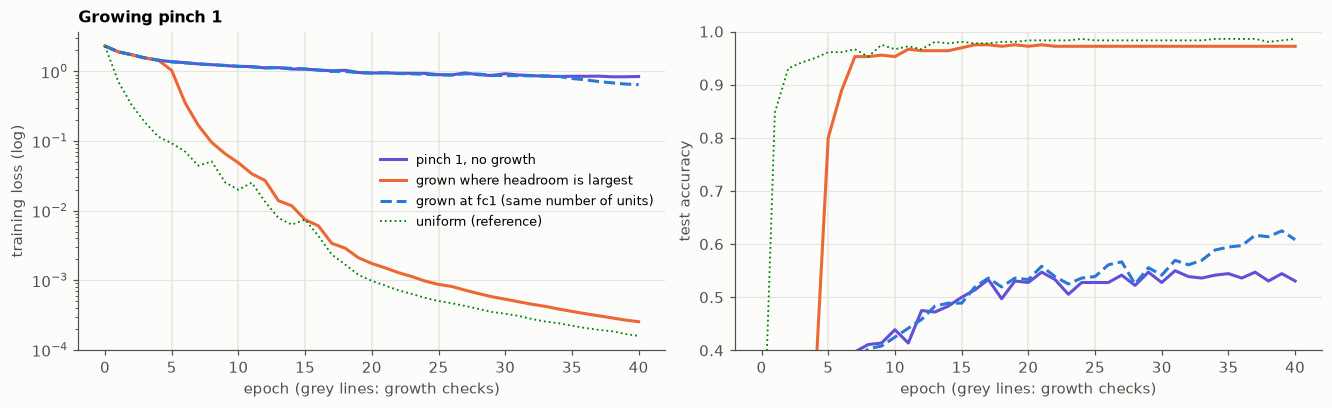

In [6]:
GROW_EPOCHS, UNITS_PER_STEP = [5, 10, 15, 20, 25], 4
growth_log = []


def make_policy(kind, grow_at=()):
    """kind "headroom": grow the best site when the check gains >= 1%. kind "fc1": grow fc1 at epochs `grow_at`."""
    def on_epoch(model, epoch):
        if kind == "none" or epoch not in GROW_EPOCHS:
            return model
        sites = {s.layer: s for s in linear_sites(model)}
        res = measure(model, list(sites.values()), FIT)
        layer = max(res, key=lambda l: res[l].headroom) if kind == "headroom" else kind
        c = check(model, sites[layer], res[layer], FIT, OTHER)
        grows = c["drop"] >= 0.01 * c["before"] if kind == "headroom" else epoch in grow_at
        if grows:
            for i in range(UNITS_PER_STEP):
                model = grow(model, sites[layer], res[layer], unit=i, scale=c["scale"])
        growth_log.append(dict(policy=kind, epoch=epoch, best_site=layer, headroom=res[layer].headroom,
                               check_drop_pct=100 * c["drop"] / c["before"], grew=grows, widths=widths_of(model)))
        return model
    return on_epoch


t0 = time.time()
GROWN = {kind: train(mlp(HIDDEN["pinch 1"]), EPOCHS, on_epoch=make_policy(kind)) for kind in ["none", "headroom"]}
grown_epochs = [r["epoch"] for r in growth_log if r["policy"] == "headroom" and r["grew"]]
GROWN["fc1"] = train(mlp(HIDDEN["pinch 1"]), EPOCHS, on_epoch=make_policy("fc1", grow_at=grown_epochs))
print(f"growth runs in {time.time() - t0:.0f}s")
display(pd.DataFrame(growth_log).round(5))
def summary(model, hist):
    return dict(widths=str(widths_of(model)), weights=sum(p.numel() for p in model.parameters()),
                **hist.iloc[-1][["train_loss", "test_acc"]])


final = pd.DataFrame({f"pinch 1, grow: {kind}": summary(m, h) for kind, (m, h, _) in GROWN.items()} |
                     {"uniform (reference)": summary(RUNS["uniform"][0], RUNS["uniform"][1])}).T
display(final)

STYLE = {"none": ("pinch 1, no growth", MODEL_COLOR["pinch 1"], "-"),
         "headroom": ("grown where headroom is largest", SITE_COLOR["fc3"], "-"),
         "fc1": ("grown at fc1 (same number of units)", SITE_COLOR["fc1"], "--")}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for kind, (_, hist, _) in GROWN.items():
    label, color, ls = STYLE[kind]
    axes[0].plot(hist.epoch, hist.train_loss, color=color, ls=ls, label=label)
    axes[1].plot(hist.epoch, hist.test_acc, color=color, ls=ls, label=label)
for ax, col in zip(axes, ["train_loss", "test_acc"]):
    ax.plot(RUNS["uniform"][1].epoch, RUNS["uniform"][1][col], color=MODEL_COLOR["uniform"], lw=1.2, ls=":",
            label="uniform (reference)")
    for e in GROW_EPOCHS:
        ax.axvline(e, color=GRID, lw=1, zorder=0)
    ax.set_xlabel("epoch (grey lines: growth checks)")
axes[0].set_yscale("log")
axes[0].set_ylabel("training loss (log)")
axes[1].set_ylabel("test accuracy")
axes[1].set_ylim(0.4, 1.0)
axes[0].legend(fontsize=8.5)
axes[0].set_title("Growing pinch 1", loc="left")
plt.show()

## What this shows

* **Only a real bottleneck is flagged.** The 1-unit `fc3` stalls training (loss 0.84, 54% test accuracy). Its
  headroom is the largest of the four layers (0.021, against 0.007 and 0.004 upstream), and adding the suggested
  unit, with no training, lowers the loss on other images by 9.5%. Upstream layers gain under 0.4%.
* **A pinch that the task can live with is not flagged.** This task fits through 3 units: `pinch 3` reaches a
  training loss of 0.001. Its headroom is ~10⁻⁶ everywhere, like the uniform model's.
* **No new `fc4` units**: they would read `fc3`'s single number, where the information is already lost (headroom 0).
* **Early**: in `pinch 1`, `fc3` leads from epoch 0. In the other two models every layer starts around 10⁻², an
  untrained model has room everywhere, and then falls.
* **Growing where it points works**: one step at epoch 5 (`fc3`: 1 → 9 units, check gain 7.7%), after which every
  check was negative, so it stopped. The grown model ends level with the uniform model (training loss 0.0003,
  97% test accuracy) with half its weights. The same 8 units added to `fc1` change almost nothing (0.65, 61%).
* The digits problem is small and easy: on it, only an extreme pinch is a capacity problem.

In [7]:
print(f"Total runtime: {time.time() - T_START:.0f}s")

Total runtime: 7s
